In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df=pd.read_csv("california_housing.csv")
print(df.head(10))
print("\n")
print(df.describe())#summary of data



   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                  41          880           129.0   
1    -122.22     37.86                  21         7099          1106.0   
2    -122.24     37.85                  52         1467           190.0   
3    -122.25     37.85                  52         1274           235.0   
4    -122.25     37.85                  52         1627           280.0   
5    -122.25     37.85                  52          919           213.0   
6    -122.25     37.84                  52         2535           489.0   
7    -122.25     37.84                  52         3104           687.0   
8    -122.26     37.84                  42         2555           665.0   
9    -122.25     37.84                  52         3549           707.0   

   population  households  median_income ocean_proximity  median_house_value  
0         322         126         8.3252        NEAR BAY              452600  
1        2401   

In [4]:
print("Shape:", df.shape)
print("\nData Types:\n", df.dtypes)
#missing values and duplicates
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate records:", df.duplicated().sum())


Shape: (20640, 10)

Data Types:
 longitude             float64
latitude              float64
housing_median_age      int64
total_rooms             int64
total_bedrooms        float64
population              int64
households              int64
median_income         float64
ocean_proximity        object
median_house_value      int64
dtype: object
Missing values:
 longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
ocean_proximity         0
median_house_value      0
dtype: int64

Duplicate records: 0


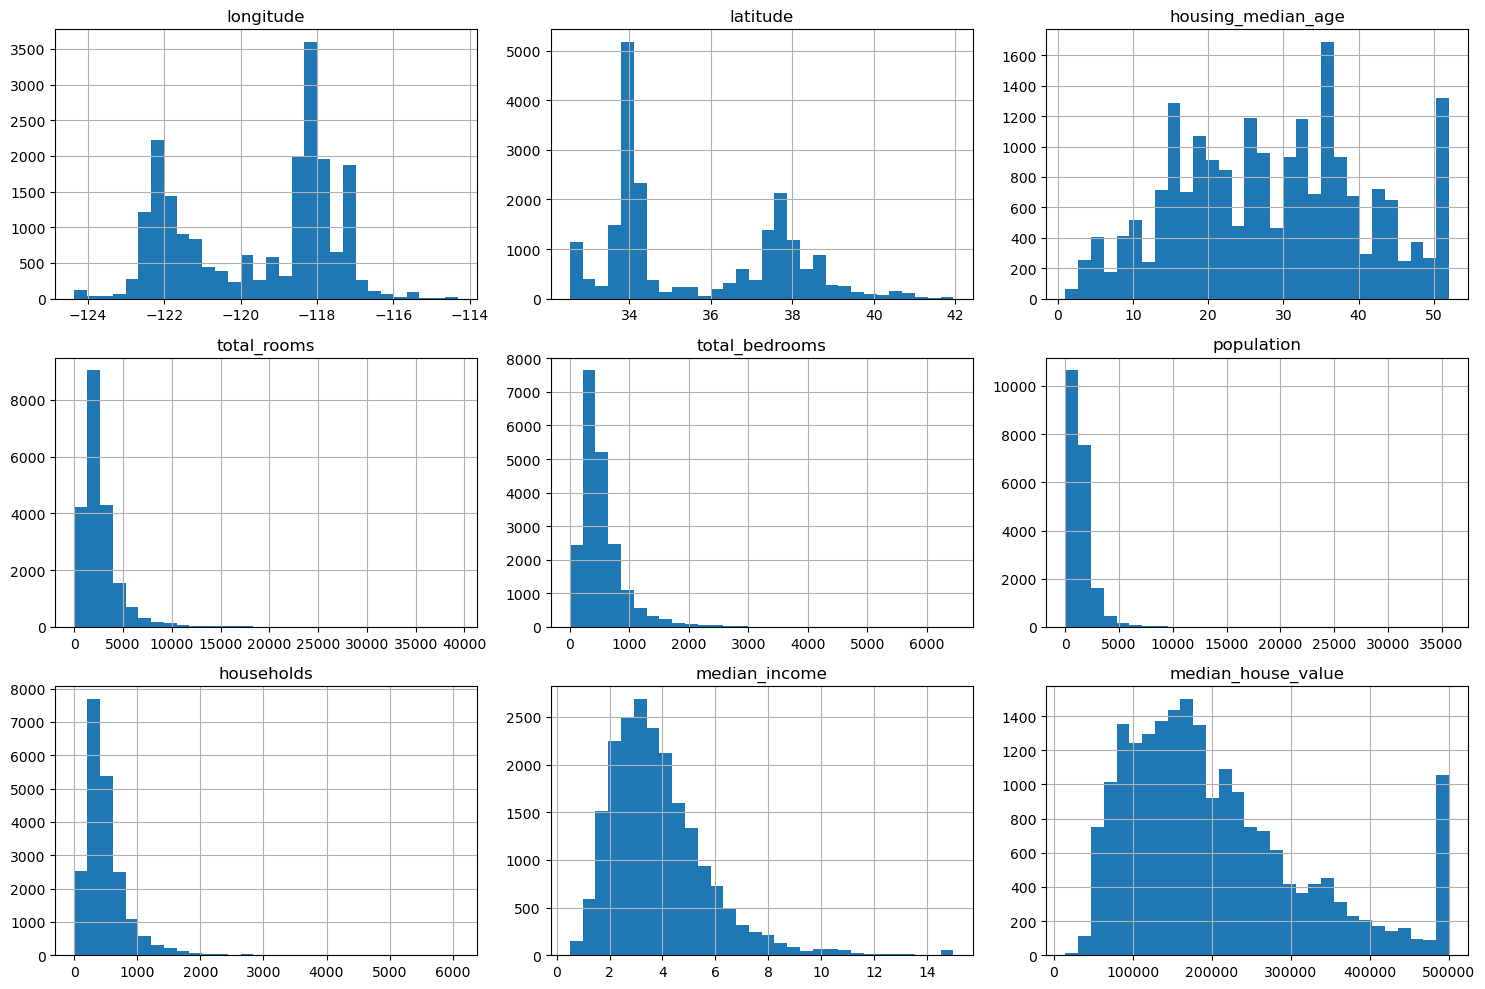

In [5]:
df.hist(bins=30, figsize=(15,10))
plt.tight_layout()
plt.show()
#histogram

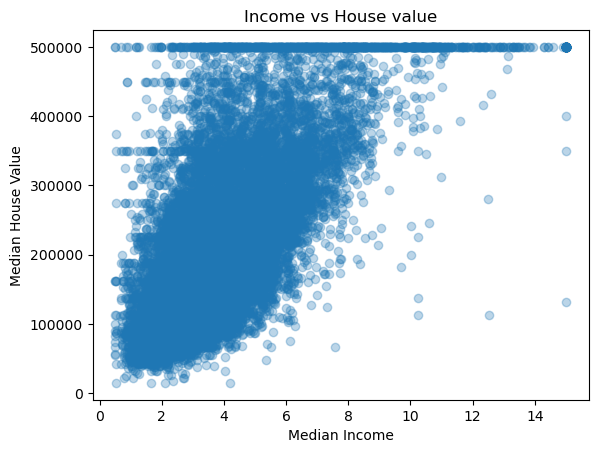

In [9]:
#scatter plot
plt.scatter(df['median_income'],df['median_house_value'],alpha=0.3)
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Income vs House value")
plt.show()


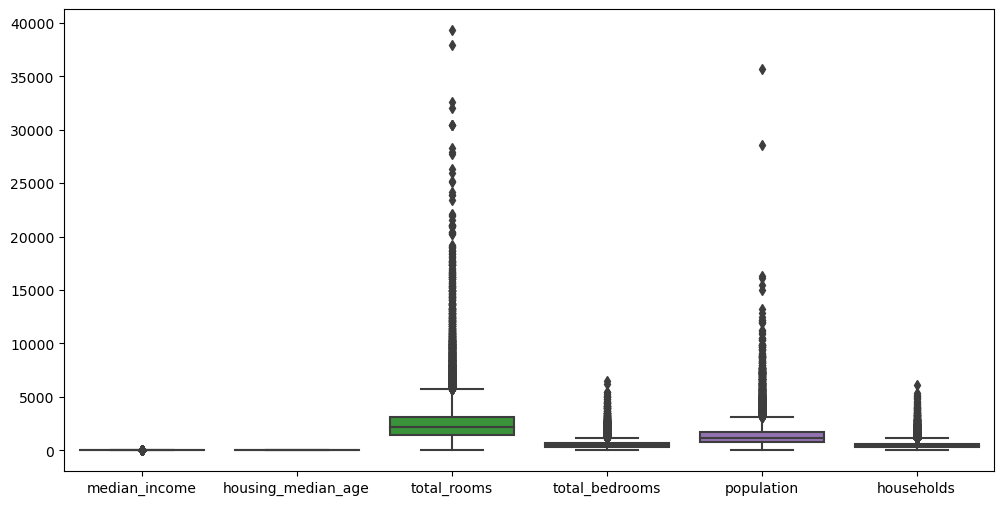

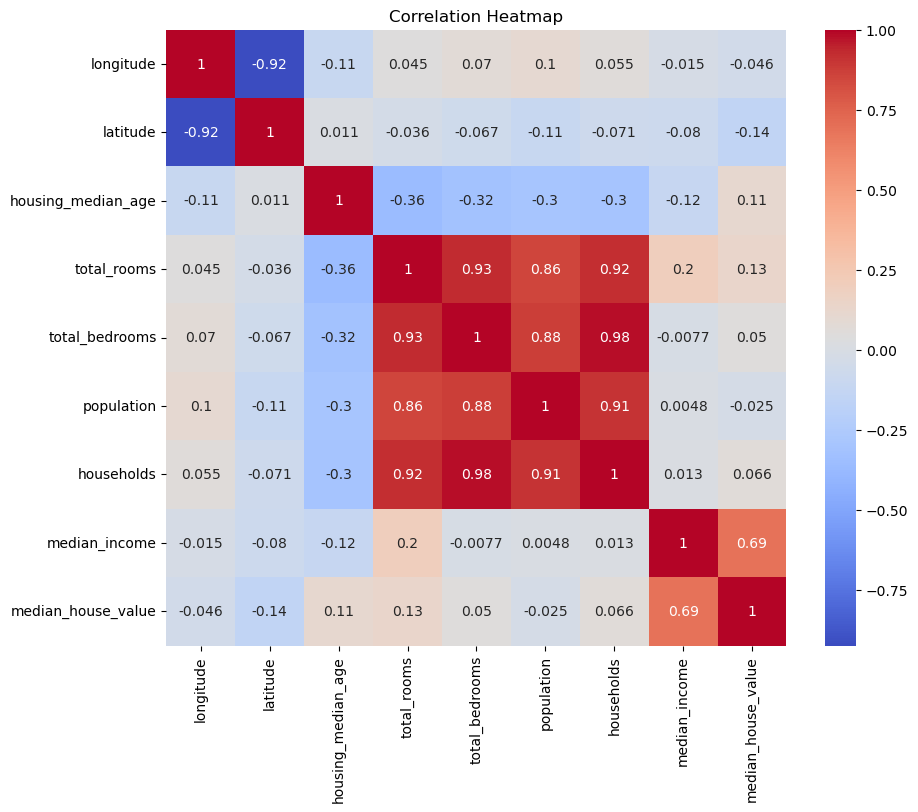

In [10]:
plt.figure(figsize=(12,6))
sns.boxplot(df[['median_income','housing_median_age','total_rooms','total_bedrooms','population','households']])
plt.show()
#correlation heatmap
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


In [22]:
import pandas as pd
from sklearn.preprocessing import StandardScaler


df = pd.read_csv("california_housing.
csv")
df = df.dropna()

# Clip outliers 
numeric_cols = df.select_dtypes(include='number').columns

lower = df[numeric_cols].quantile(0.01)
upper = df[numeric_cols].quantile(0.99)

df[numeric_cols] = df[numeric_cols].clip(
    lower=lower,
    upper=upper,
    axis=1
)

#Separate features and target

X = df.drop(['median_house_value', 'ocean_proximity'], axis=1)
y = df['median_house_value']

#Scaling numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("X shape:", X_scaled.shape)
print("y shape:", y.shape)

X shape: (20433, 8)
y shape: (20433,)


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape, "Testing set:", X_test.shape)


Training set: (16346, 8) Testing set: (4087, 8)


In [25]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import time


In [26]:
def evaluate_model(model, X_train, y_train, X_test, y_test):
    start = time.time()
    model.fit(X_train, y_train)
    end = time.time()
    
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    exec_time = end - start
    
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2, "Time": exec_time}


In [27]:
# Correlation with target
corr = df.corr(numeric_only=True)['median_house_value'].sort_values(ascending=False)
print(corr)


top3 = corr.index[1:4].tolist()
print("Top 3 features:", top3)




median_house_value    1.000000
median_income         0.696638
total_rooms           0.148538
housing_median_age    0.106877
households            0.069753
total_bedrooms        0.053295
population           -0.029779
longitude            -0.045427
latitude             -0.143189
Name: median_house_value, dtype: float64
Top 3 features: ['median_income', 'total_rooms', 'housing_median_age']


In [35]:


# Model A: Top 3 correlated features
X_train_A = X_train[:, [X.columns.get_loc(c) for c in top3]]
X_test_A  = X_test[:, [X.columns.get_loc(c) for c in top3]]

modelA = LinearRegression()
resultsA = evaluate_model(modelA, X_train_A, y_train, X_test_A, y_test)

# slecting top 5 correlated features 
selected5 = ['median_income','housing_median_age','total_rooms','population','households']
X_train_B = X_train[:, [X.columns.get_loc(c) for c in selected5]]
X_test_B  = X_test[:, [X.columns.get_loc(c) for c in selected5]]

modelB = LinearRegression()
resultsB = evaluate_model(modelB, X_train_B, y_train, X_test_B, y_test)

# Model C: All features
modelC = LinearRegression()
resultsC = evaluate_model(modelC, X_train, y_train, X_test, y_test)


In [36]:
results = pd.DataFrame({
    "Model A (Top 3)": resultsA,
    "Model B (5 features)": resultsB,
    "Model C (All features)": resultsC
})

results


,Model A (Top 3),Model B (5 features),Model C (All features)
MAE,6.093980e+04,5.698135e+04,5.041343e+04
MSE,6.649672e+09,5.894383e+09,4.802174e+09
RMSE,8.154552e+04,7.677488e+04,6.929772e+04
R2,5.137416e-01,5.689722e-01,6.488402e-01
Time,2.867937e-03,3.581047e-04,1.611781e-02


In [44]:
import pandas as pd, numpy as np, time
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.feature_selection import RFE
from sklearn.preprocessing import StandardScaler

# Load and preprocess
df = pd.read_csv("california_housing.csv").dropna()
df = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True)
X, y = df.drop('median_house_value', axis=1), df['median_house_value']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)


In [48]:
def eval_model(model, X_train, Y_train, X_testing, Y_testing):
    start = time.time(); model.fit(X_training, Y_training); end = time.time()
    ypred = model.predict(X_testing)
    return {
        "MAE": mean_absolute_error(Y_testing, ypred),
        "MSE": mean_squared_error(Y_testing, ypred),
        "RMSE": np.sqrt(mean_squared_error(Y_testing, ypred)),
        "R2": r2_score(Y_testing, ypred),
        "Time": end-start
    }


In [46]:
lr = LinearRegression()
selector = RFE(lr, n_features_to_select=5)   # choose top 5 features
selector.fit(X_train, y_train)

selected_idx = np.where(selector.support_)[0]
X_train_sel, X_test_sel = X_train[:, selected_idx], X_test[:, selected_idx]


In [47]:
results_all = eval_model(LinearRegression(), X_train, y_train, X_test, y_test)
results_sel = eval_model(LinearRegression(), X_train_sel, y_train, X_test_sel, y_test)

pd.DataFrame({"All Features": results_all, "Selected Features": results_sel})


,All Features,Selected Features
MAE,5.041343e+04,5.268172e+04
MSE,4.802174e+09,5.149941e+09
RMSE,6.929772e+04,7.176309e+04
R2,6.488402e-01,6.234096e-01
Time,6.995916e-03,2.996922e-03
